## Random Forest: How the Sampling Works:

A random forest is a group of decision trees, where each tree is trained on a different random view of the data. The trees then **vote** on the final prediction.
This notebook builds that idea by hand with plain `DecisionTreeClassifier`, one sampling strategy at a time:

1. **Row sampling:** each tree gets a random sample of the rows, drawn with replacement (a bootstrap sample)
2. **Column sampling:** each tree gets a random subset of the columns
3. **Combined sampling:** both at once

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_classification
from sklearn.tree import DecisionTreeClassifier, plot_tree

RANDOM_STATE = 42	# Set this to None for different results on every run
np.random.seed(RANDOM_STATE)

In [2]:
FEATURES = ["col1", "col2", "col3", "col4", "col5"]

X, y = make_classification(n_features=5, n_redundant=0, n_informative=5, n_clusters_per_class=1, random_state=RANDOM_STATE)

In [3]:
df = pd.DataFrame(X, columns=FEATURES)
df["target"] = y

print(df.shape)
df.head()

(100, 6)


,col1,col2,col3,col4,col5,target
0,1.053909,-3.861208,1.530963,0.596692,1.030284,0
1,3.243492,1.666651,3.179016,-0.825861,0.778528,1
2,0.712446,-1.201617,1.528624,-0.422788,-0.376825,0
3,1.388329,1.538995,1.243716,0.740905,-2.081063,1
4,2.394647,-3.576345,0.914217,0.363136,2.110329,0


### Helper functions:

The sampling helpers each return a new DataFrame, and the target column always stays last.

In [4]:
def sample_rows(df, percent):
    return df.sample(round(percent * df.shape[0]), replace=True)

In [5]:
def sample_features(df, percent):
    feature_cols = [c for c in df.columns if c != "target"]
    chosen = np.random.choice(feature_cols, max(1, round(percent * len(feature_cols))), replace=False).tolist()

    return df[chosen + ["target"]].copy()

In [6]:
def combined_sampling(df, row_percent, col_percent):
    return sample_features(sample_rows(df, row_percent), col_percent)

In [7]:
def split_xy(data):
    return data.drop(columns="target"), data["target"]

def show_tree(clf):
    plt.figure(figsize=(10, 6))
    plot_tree(clf, feature_names=list(clf.feature_names_in_), filled=True)
    plt.show()

def majority_vote(clfs, query):
    votes = [int(clf.predict(query[clf.feature_names_in_])[0]) for clf in clfs]
    return votes, int(np.bincount(votes).argmax())

One new data point to classify. Trees trained on fewer columns will only look at the columns they know, so the same point works in every section below.

In [8]:
query = pd.DataFrame([[0.547930, -3.520534, -2.275349, -1.066693, -1.997992]], columns=FEATURES)
query

,col1,col2,col3,col4,col5
0,0.54793,-3.520534,-2.275349,-1.066693,-1.997992


## 1. Row Sampling:

In [9]:
df1 = sample_rows(df, 0.4)
df2 = sample_rows(df, 0.4)
df3 = sample_rows(df, 0.4)

Because rows are drawn **with replacement**, a sample can contain the same row more than once. For example, here is a sample of 14 rows from the full data:

In [10]:
df.sample(14, replace=True)

,col1,col2,col3,col4,col5,target
34,0.243170,2.502042,2.874533,1.795390,0.798094,1
32,2.088315,-1.247805,1.486723,0.135038,1.115911,0
4,2.394647,-3.576345,0.914217,0.363136,2.110329,0
40,1.084541,-2.416953,0.527332,1.767058,2.016924,0
27,0.040396,-0.240705,0.080784,3.017119,1.675806,0
6,1.141112,2.049215,0.628753,1.427840,0.819933,0
72,1.278946,0.942680,1.595688,0.610217,-1.573149,1
71,0.449238,0.019996,-0.412447,1.197078,-2.842476,1
11,-0.244491,1.626095,1.559328,2.087291,-0.551479,1
33,2.070481,-1.264344,0.055554,1.442043,2.373943,0


In [11]:
clf1 = DecisionTreeClassifier(random_state=RANDOM_STATE)
clf2 = DecisionTreeClassifier(random_state=RANDOM_STATE)
clf3 = DecisionTreeClassifier(random_state=RANDOM_STATE)

In [12]:
clf1.fit(*split_xy(df1))
clf2.fit(*split_xy(df2))
clf3.fit(*split_xy(df3))

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

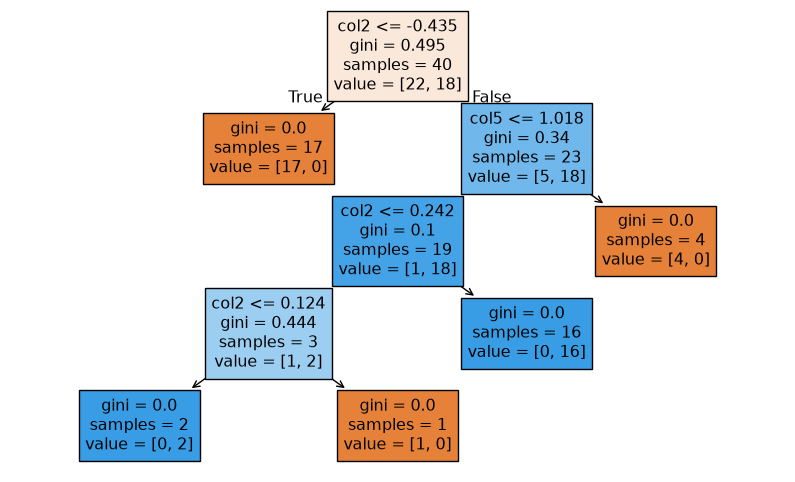

In [13]:
show_tree(clf1)

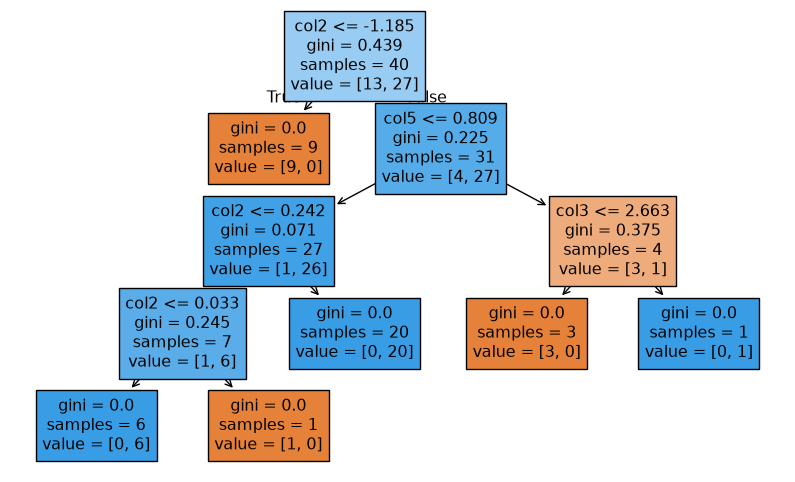

In [14]:
show_tree(clf2)

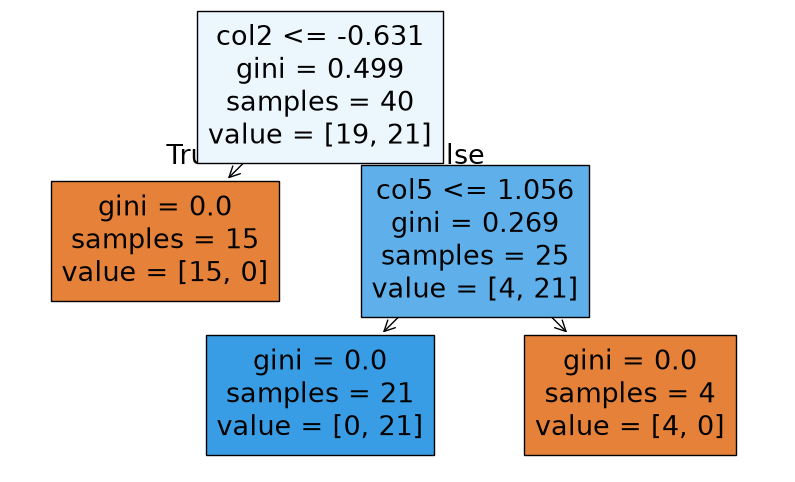

In [15]:
show_tree(clf3)

In [16]:
clf1.predict(query[clf1.feature_names_in_])

array([0])

In [17]:
clf2.predict(query[clf2.feature_names_in_])

array([0])

In [18]:
clf3.predict(query[clf3.feature_names_in_])

array([0])

Each tree has its own opinion. The forest's answer is the majority vote:

In [19]:
votes, final = majority_vote([clf1, clf2, clf3], query)
print(f"Votes: {votes}  ->  forest prediction: {final}")

Votes: [0, 0, 0]  ->  forest prediction: 0


## 2. Column Sampling:

In [20]:
df1 = sample_features(df, 0.8)
df2 = sample_features(df, 0.8)
df3 = sample_features(df, 0.8)

In [21]:
print(df1.columns.tolist())
print(df2.columns.tolist())
print(df3.columns.tolist())

['col4', 'col1', 'col2', 'col3', 'target']
['col2', 'col4', 'col5', 'col1', 'target']
['col5', 'col2', 'col4', 'col1', 'target']


In [22]:
clf1 = DecisionTreeClassifier(random_state=RANDOM_STATE)
clf2 = DecisionTreeClassifier(random_state=RANDOM_STATE)
clf3 = DecisionTreeClassifier(random_state=RANDOM_STATE)

In [23]:
clf1.fit(*split_xy(df1))
clf2.fit(*split_xy(df2))
clf3.fit(*split_xy(df3))

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

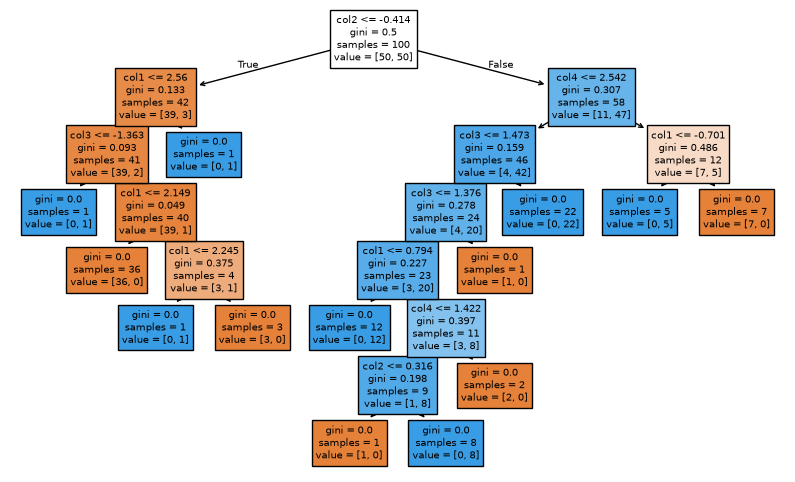

In [24]:
show_tree(clf1)

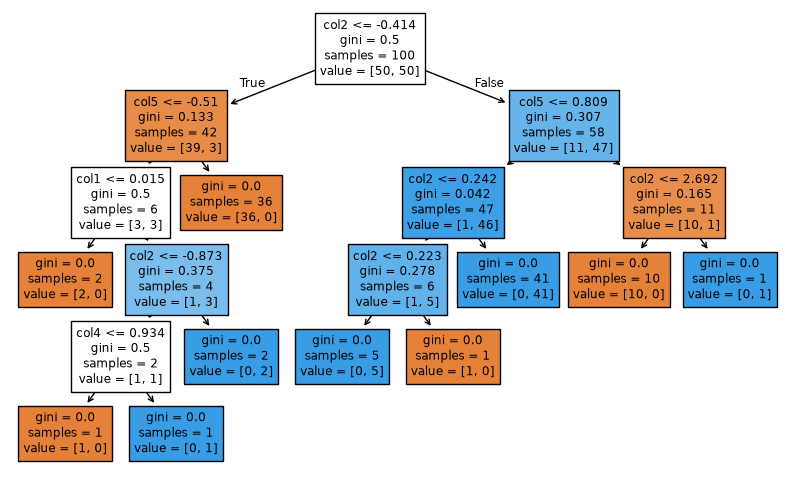

In [25]:
show_tree(clf2)

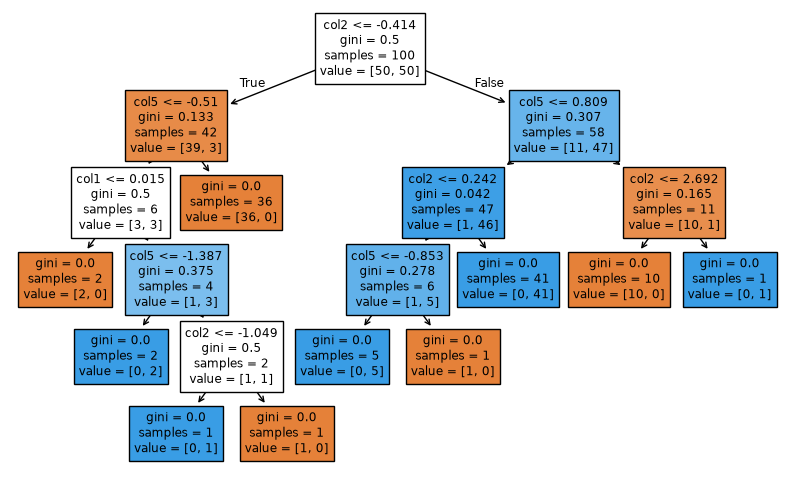

In [26]:
show_tree(clf3)

In [27]:
clf1.predict(query[clf1.feature_names_in_])

array([1])

In [28]:
clf2.predict(query[clf2.feature_names_in_])

array([0])

In [29]:
clf3.predict(query[clf3.feature_names_in_])

array([1])

In [30]:
votes, final = majority_vote([clf1, clf2, clf3], query)
print(f"Votes: {votes}  ->  forest prediction: {final}")

Votes: [1, 0, 1]  ->  forest prediction: 1


## 3. Combined Sampling:

In [31]:
df1 = combined_sampling(df, 0.5, 0.5)
df2 = combined_sampling(df, 0.5, 0.5)
df3 = combined_sampling(df, 0.5, 0.5)

In [32]:
print(df1.columns.tolist())
print(df2.columns.tolist())
print(df3.columns.tolist())

['col5', 'col4', 'target']
['col5', 'col2', 'target']
['col5', 'col2', 'target']


In [33]:
clf1 = DecisionTreeClassifier(random_state=RANDOM_STATE)
clf2 = DecisionTreeClassifier(random_state=RANDOM_STATE)
clf3 = DecisionTreeClassifier(random_state=RANDOM_STATE)

In [34]:
clf1.fit(*split_xy(df1))
clf2.fit(*split_xy(df2))
clf3.fit(*split_xy(df3))

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

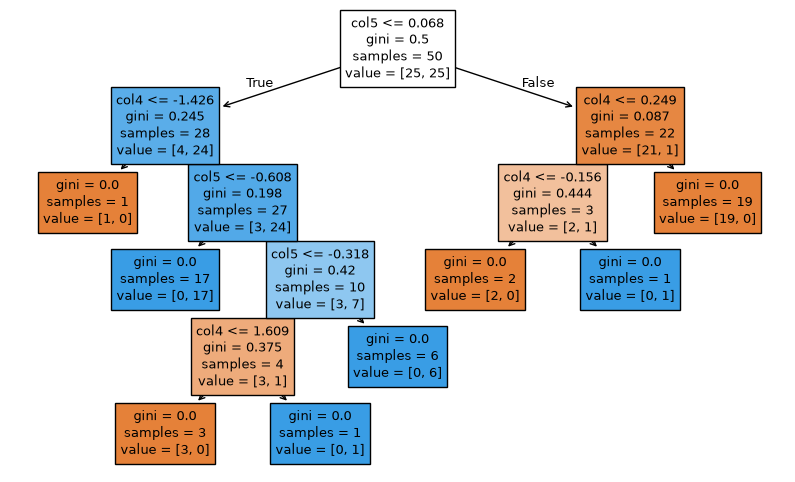

In [35]:
show_tree(clf1)

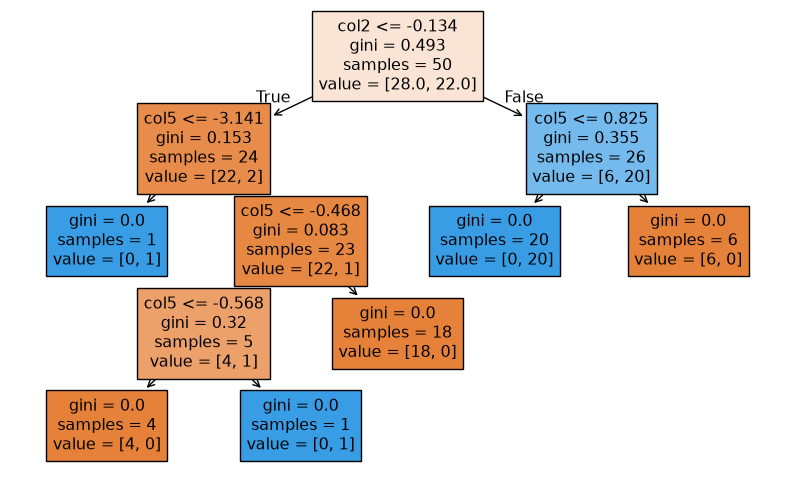

In [36]:
show_tree(clf2)

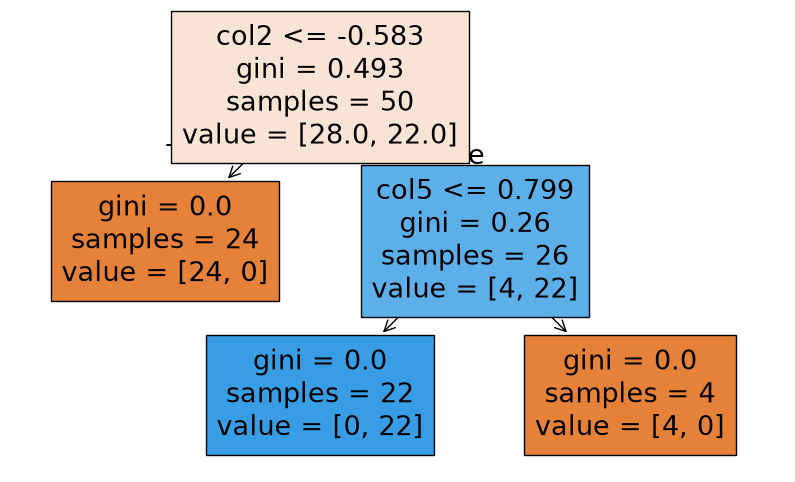

In [37]:
show_tree(clf3)

In [38]:
clf1.predict(query[clf1.feature_names_in_])

array([1])

In [39]:
clf2.predict(query[clf2.feature_names_in_])

array([0])

In [40]:
clf3.predict(query[clf3.feature_names_in_])

array([0])

In [41]:
votes, final = majority_vote([clf1, clf2, clf3], query)
print(f"Votes: {votes}  ->  forest prediction: {final}")

Votes: [1, 0, 0]  ->  forest prediction: 0
